# Ground state preparation with dynamical cooling

In this tutorial our goal is to **prepare the ground state of a physical system**. This task is usually tackled by starting from an initial state that already has a good-enough overlap with the ground state. The algorithm provided by [Motlagh et al.](https://arxiv.org/abs/2404.05810) suggest a dynamical approach where we iteratively lower the state's energy and increase the overlap with the ground state. The core of the algorithm is that **the cooling works for any initial state** - even without initial overlap with the ground state, although of course some states will perform better than others.

This tutorial is structured in the following way: First, the [steps of the algorithm](#the-idea-of-dynamical-cooling) are explained. We then visualize the time evolution of the cooling process by computing the [time evolution for a small example](#theoretical-prediction-for-the-3-qubit-xy-model). Lastly, we [implement the algorithm](#implementation-in-qrisp) in Qrisp, using some simplifications, to demonstrate the cooling from an exited state to the ground state.

## The idea of dynamical cooling

Before explaining the steps, we want to introduce the main ingredients of the algorithm.
First, we need our **system Hamiltonian** $H_S$ that describes the properties of our physical system as well as an **initial state** $\ket{\Psi_i}$.
The initial state can be any superposition of eigenstates of the Hamiltonian. There needs not to be an overlap with the groundstate, but
the choice of the initial state will have an impact on the efficiency of the algorithm, i.e. the necessary evolution time and number of iterations.

The next ingredient is a **perturbation operator** $A$ that will be used to move from $\ket{\Psi_i}$ to energetically lower states.
One choice could be a transverse field operator, but the optimal choice of $A$ is not uniquely defined.

Lastly, we need an operator that approximates a **step function**. The step function seperates the eigenstates of $H_S$ into a 
lower subspace where all eigenstates with $E_i < \epsilon$ have eigenvalue $-1$ and an upper subspace where all eigenstates $E_i > \epsilon$ have eigenvalue $+1$.
The subspaces are defined by the threshold value $\epsilon$.

Having collected all the elements of the algorithm, let's move through each step.

### Step 1: QPE

We apply the [Quantum Phase Estimation Algorithm](../../reference/Primitives/QPE.rst) (QPE) to our inital state with the trotterized system Hamiltonian as the unitary operator. This will project the state into an eigenstate $\ket{\lambda_j}$ and gives us the corresponging phase $\Theta_j$ from which we can get the eigenvalue of the state. The probability of each state is proportional to the amplitude in the superposition of $\ket{\Psi_i}$. Now our system is in the state $\ket{\lambda_j}$ and has the corresponding eigenvaule $E_j$.

There also exists a block encoding based approach where one can use [QSVT (Quantum Singular Value Transformation)](../../reference/Algorithms/GQSP.rst) instead of QPE. We refer to the original paper for more details on this approach. For the remainder of this tutorial we will stick with the QPE version.

### Step 2: Create evolution operator $\tilde{H}$

Next we calculate the step operator with the threshold at the eigenvalue from the step before $\epsilon = E_j + \zeta$ where $\zeta$ is a small tolerance parameter.
Adding our perturbation operator $A$ to the step operator, we create a new Hamiltonian $\tilde{H}$ under which we will evolve our system. 

$\tilde{H} = H_{step} + \sqrt{\delta} / 2 A$.

The parameter $\delta \in (0, 1]$ determines the strength of the perturbation.

### Step 3: Time evolution

This is the core of the algorithm. The perturbation operator can induce transitions between states, as long as the systems energy is conserved. Since the states within each subspace are degenerate with eigenvalue $\pm 1$, transitioning from one state with $E_j < \epsilon$ to another state $E_k < \epsilon$ will leave the total energy unchanged. The same is valid for the upper subspace of course. The time evolution under a certain time $t$ looks like this:

$\ket{\Psi(t)} = e^{-i\tilde{H}t} \ket{\lambda_j}$

As our system is in state $\ket{\lambda_j}$ at the beginning of the evolution and its eigenvalue is slightly lower than the threshold value, transitions to states with lower energy are favored while transitions to the $+1$ subspace are far less likely. After an optimal time $t_{opt}$, our system is in a superposition of states with high amplitude for energetically lower states. Applying QPE on this state will thus most likely lead to a collapse into an energetically lower wave function.

### Repeat

We now start again from step 1 with the QPE, leading to a projection onto a lower state, a smaller threshold value in step 2 and evolving under the new evolution operator. We can stop the algorithm once we do not lower the energy anymore or we reach a certain defined threshold value.

If this description has felt a bit cryptic so far, don't worry: We will cover the steps with some explanatory visuals in the example for the 3-Qubit XY-Model.

<!-- - Start from any state of the Hamiltonian as a initial state
1. Apply quantum phase estimation -> projects inital state onto an eigenstate $\ket{\Phi_j}$ with eigenvalue $E_j$
2. Calculate polynomial that applies step function (with step at $E_j$) onto Hamiltonian -> separates Hilbert space into two subspaces with eigenvalues $\pm 1$
3. Let this modified Hamiltonian evolve under the perturbation operator for a time $t$ -> induces transitions within each subspace, favors the states with higher overlap with lower energy states? 
4. Quantum phase estimation -> induces collapse of superposition of states into a lower energy state
- Repeat from step 2 with a lower step value until no more change or a critial value is reached

&rarr; Iterative lowering of the energy of the system -->

## The role of Block Encodings

Before moving on to the examples, we need to cover one issue: The Step Operator is a **non-unitary** operator, but quantum circuits are always reversible and thus can only describe unitary dynamics. So we need to include an additional step to realize the step- and evolution operator. 

This is where block encodings come into play: They encode a non-unitary matrix into a unitary one with the cost of a higher dimension. With the block encoding we can then execute the time evolution. We have got a whole Qrisp [BlockEncoding](../../reference/Block%20Encodings/index.rst) module that includes basic matrix arithmetic as well as more complex algorithms like Singular Value Transform. You can find out more about the basics of BlockEncodings in [this](../tutorial/BE_tutorial/index.rst) tutorial.

## Theoretical prediction for the 3-Qubit XY-Model

In this section we want to illustrate the evolution under the perturbed step operator. For this we create the evolution operator for the example of a XY-Hamiltonian and clasically compute the time evolution. This will add some physical intuition to the algorithm before we use a quantum simulator where we will only see the results after each iterative step.

Our system is described by a XY-Hamiltonian. This means we have next-neighbour $X$ and $Y$ interactions. Additionally we have a local $X$-potential.

$\hat{H} = \sum_{i=1}^{2} (J_i^{x} X_i X_{i+1} + J_i^{y} Y_i Y_{i+1}) + \sum_{i=1}^{3} h_i X_i$

The spectrum of the system is shown in the figure below. We have got 8 non-degenerate states with corresponging eigenvalues. The Hamiltonian is normalized to $||H|| \leq 1$.

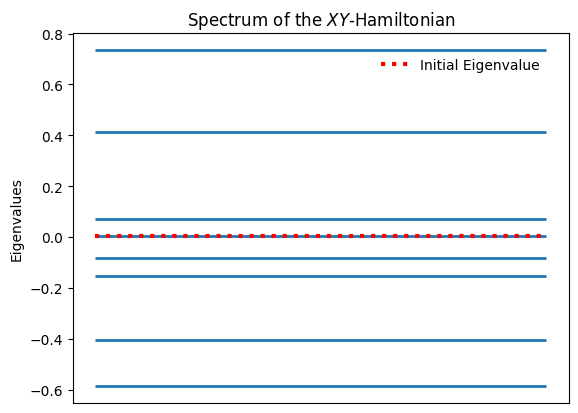

For the initial state we choose the eigenvector of the 4th eigenvalue $\ket{\lambda_4}$ with $E_4 \approx 0.004$. We take a transversal field as our perturbation operator, in this case a $Z$-field:

$\hat{A} = \sum_{i=1}^{3} Z_i$

The evolution operator for the first iteration will be:

$\tilde{H} = H_{step}(E_4+\zeta) + \frac{\sqrt{\delta}}{2} A$.

The step function is approximated as a Chebyshev polynomial of the error function, which is defined as:

$\mathrm{erf}(x) = \frac{2}{\sqrt{\pi}} \int_0^x e^{-t^2}dt.$

We use a tolerance paramter $\zeta$ which moves the step function slightly to the right, i.e. to higher energies: $\mathrm{erf}(x-\epsilon) \rightarrow \, \mathrm{erf}(x-(\epsilon+\zeta))$. This moves the energy threshold that separates the subspaces slightly up which makes sure that our current energy is comfortably in the lower energy subspace and we stay in this subspace during the time evolution.
Secondly, we scale the error function slightly to ensure that its images stays within $[-1, 1]$. Lastly, in the code implementation is a ''sharpness'' parameter which amplifies the argument of the sign function and makes the step more steep.
For a polynomial of degree 30 and sharpness 20 we find the following approximation:

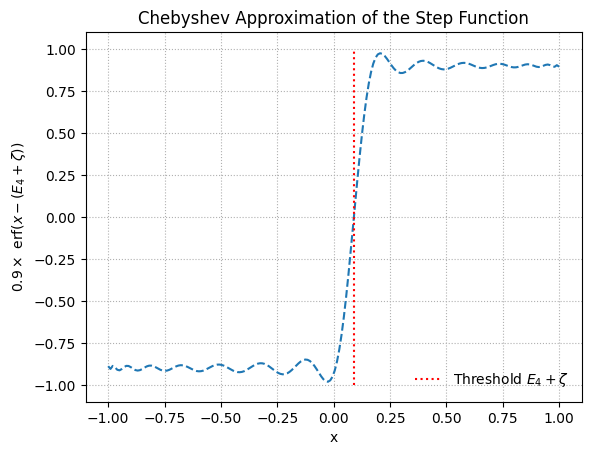

We use the tolerance $\zeta = 0.05$ that shifts the theshold to higher energies and a moderate perturbation strength $\delta = 0.6$. Now we simply compute the time evolution for a span $t \in [0, 10]$ and observe how the system evolves.

$\ket{\Psi(t)} = e^{-i/\hbar \tilde{H} t} \ket{\lambda_4}$

To understand the effect of the perturbation we calculate the overlap of $\ket{\Psi(t)}$ with the other eigenstates. This is shown in the figure below. We can identify a maximum overlap with the next lower state $\ket{\lambda_3}$ at around $t\approx 4$. We even see an emerging overlap with $\ket{\lambda_2}$ after a longer time. Note that $t$ plays the role of a dimensionless time, since the Hamiltonian is in dimensionless units as well.

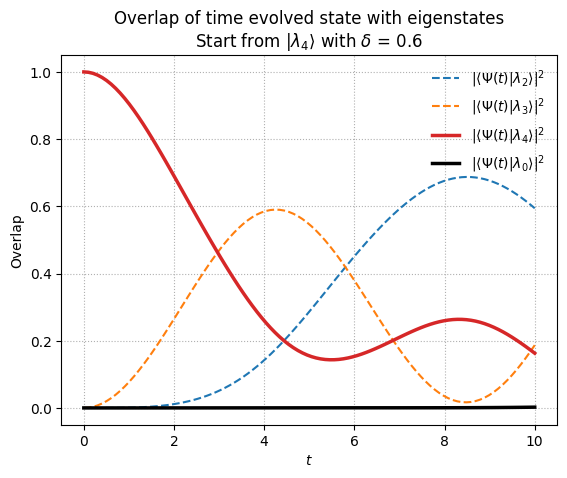

Running QPE with sufficient precision after $t\approx 4$, we measure the next lower energy with a probabilty around 60%. If we measure the wavefunction it also means that our system is now in the next lower state. Using this algorithm iteratively, we can go as far as to the ground state.

One challenge though is the dependence of the optimal evolution time on the energy landscape of the Hamiltonian.
This might lead to long evolution times and/or strong perturbation strengths $\delta$ that are needed to transition to lower states which will in turn lead to a higher scaling factor of the Block Encoding and longer runtimes.
This is the reason why we will show a simplified example to execute the algorithm on our quantum simulator.


## Implementation in Qrisp

Now we will implement the algorithm using Qrisp. We again use the 3-Qubit XY-Model, but we will use a different perturbation operator in order to make things faster and more stable. 
You have seen that the Z-Field induces low-energy transitions with a probability of around 60% after $t\approx 4$. For lower energy states, the evolution time needed is even longer or does not reach a high overlap with the next lower state at all. Since we know the spectrum and eigenstates of the Hamiltonian, we will simply construct our perturbation operator as a projector onto the next lower state. This will speed up the process and it suffices to demonstrate the workings of the algorithm. The operator for the $i$-th eigenstate is:

$A_i = \ket{\lambda_{i-1}} \bra{\lambda_i} + \ket{\lambda_{i}} \bra{\lambda_{i-1}}$.


We start by importing some modules that we will need:

In [3]:
import os

# Ensure high precision for the simulator
os.environ["QRISP_SIMULATOR_FLOAT_THRESH"] = "1e-10"
os.environ["QRISP_SIMULATOR_CUTOFF_RATIO"] = "1e-10"

from functools import partial
import jax
import jax.numpy as jnp
import numpy as np

from qrisp import measure, prepare, QuantumVariable, QPE, reset
from qrisp.block_encodings import BlockEncoding
from qrisp.jasp import jaspify, qache, q_while_loop, RUS
from qrisp.operators import X, Y

Now we set up a method to calculate the coefficients for the Chebychev approximation of the step function. Since we will use Jasp for optimized compilation and support for real-time
hybrid computation, we need to define it in a Jasp-compatible way. If you want to learn more about Qrisp’s Jax-based compilation infrastructure, you can read [this tutorial](../../reference/Jasp/index.rst). We further use the jax.jit (Just-in-Time) module to speed-up the calculation of the coefficients.

In [4]:
@partial(jax.jit, static_argnames=["degree", "sharpness"])
def get_step_coeffs(threshold, degree=5, sharpness=20.0):
    """
    Gives Chebyshev coefficients for the error function 
    using JAX-compatible operations.
    """
    def sign_target(x):
        return jax.scipy.special.erf(sharpness * (x - threshold)) * 0.9

    n_nodes = 201
    x_nodes = jnp.cos(jnp.pi * np.arange(n_nodes) / (n_nodes - 1))
    y_nodes = sign_target(x_nodes)

    # Construct Chebyshev Vandermonde matrix using recurrence
    def body_fn(i, val):
        T_prev2 = val[:, i-2]
        T_prev1 = val[:, i-1]
        T_curr = 2.0 * x_nodes * T_prev1 - T_prev2
        return val.at[:, i].set(T_curr)

    V = jnp.zeros((n_nodes, degree + 1))
    V = V.at[:, 0].set(jnp.ones_like(x_nodes))
    V = V.at[:, 1].set(x_nodes)
    V = jax.lax.fori_loop(2, degree + 1, body_fn, V)

    coeffs, _, _, _ = jnp.linalg.lstsq(V, y_nodes, rcond=None)
    return coeffs



The next function we define, prepares the given quantum variable in a specific eigenstates. We will use this later to define the perturbation operator step-wise.

In [5]:
@qache
def cached_prepare(qv, state):
    prepare(qv, state, method="qswitch", reversed=True)



<!-- To run the algorithm, we will use a RUS (repeat until success) decorator and a while loop that will run until our maximum number of cycles has been reached. In each step of a successfully completed cycle we will return the energy after the QPE.  -->

Since the algorithm is iterative we will define a function that executes a single iteration of the algorithm. This function is later applied in a while-loop that stops after a certain number of cooling steps. One iteration is structured in the following way:

1. Perform QPE and save the energy $E_i$ in an array.
2. Calculate the coefficients for the step polynomial with the new threshold $E_i$.
3. Apply the polynomial to the block-encoded Hamiltonian.
4. Build the perturbation operator $A_i$ as defined above.
5. Build the time evolution block encoding: $\exp(-i (H_{step} + H_{pert}) t)$.
6. Apply this block encoding to the QuantumVariable.
7. Measure and clean up ancilla qubits, return success-flag.

Two remarks should be made about the steps:

BlockEncodings are not applied with a success probabilty of 100% in general. This is why we need a success-flag which is encoded in the ancilla qubits. But note the last step where we apply the simulation block encoding: We actually encode a unitary operator here, since the time evolution operator is always unitary. This is what leads to a close to 1 success probability of the BlockEncoding application, for sufficiently large truncation of the series $N$.

Secondly, this calculation combines both quantum simulation and clasically challenging calculations (calculating the QPE energy and the polynomial coefficients). This is only possible because we run the code within the Jasp pipeline. In a solely circuit-based run, it would not be possible to do those calculations while keeping a coherent quantum state.


In [ ]:
def perform_cooling_iteration(
    operand, qpe_unitary, iteration, eigenstates, init_index,H_BE, delta, t, e_steps
):
    """
    Perform one iteration of the dynamical cooling algorithm.
    
    Returns: updated operand, success flag, and energy steps
    """
    # Stpe 1: Perform QPE
    qpe_result = QPE(operand, qpe_unitary, kwargs={"steps": 2}, precision=9)
    theta = measure(qpe_result)
    reset(qpe_result)
    qpe_result.delete()
    theta = jnp.where(theta > 0.5, theta - 1.0, theta)
    E = 2*np.pi*theta
    E = jnp.clip(E, -1.0, 1.0)
    e_steps = e_steps.at[iteration].set(E)

    # Step 2: Calculate coefficients for step function and build BE
    sign_coeffs = get_step_coeffs(threshold=E+0.05)
    # Step 3: Apply step function to the Hamiltonian
    step_BE = H_BE.poly(sign_coeffs, kind="Chebyshev")

    # Step 4: Create perturbation operator for this iteration
    def prep_left(qv):
        cached_prepare(qv, eigenstates[:, init_index-1-iteration])
    def prep_right(qv):
        cached_prepare(qv, eigenstates[:, init_index-iteration])

    projector_BE = BlockEncoding.from_projector(left=prep_left, right=prep_right)
    pert_BE = jnp.sqrt(delta) * (projector_BE + projector_BE.dagger())

    # Step 5: Build time evolution BE 
    simulation_BE = step_BE + pert_BE
    evol_BE = simulation_BE.sim(t, N=10)

    # Step 6: Apply evolution BE
    ancillas = evol_BE.apply(operand)
    bools = jnp.array([measure(anc) == 0 for anc in ancillas])
    success = jnp.all(bools)
    # Step 7: Reset and delete ancillas
    for anc in ancillas:
        reset(anc)
        anc.delete()
    
    return operand, success, e_steps

Now we put the algorithm together! We use a [Repeat-Until-Success (RUS)](../../reference/Jasp/Control%20Flow/RUS.rst) decorator that applies the block encoding until we have reached success. The RUS decorator has to cover the multi-step cooling function. This function in turn creates the while-loop by defining a condition- and body-function. The first tells the loop when to stop, in our case if a number of iteration cycles is reached. And the body function executes the cooling iteration from above. The multi-step function also creates the QuantumVariable in the initial state and applies the QPE after the last iteration. It then returns the energy steps that were measured.



In [38]:
@RUS
def perform_multi_step_cooling(N, H_BE, qpe_unitary, delta, t, N_cycles, init_index, eigenstates_jax):
    
    # Condition function for while loop
    def cond_fun(val):
        iteration, operand, success, e_steps = val
        return success & (iteration < N_cycles)
    
    # Body function for while loop
    def body_fun(val):
        iteration, operand, success, e_steps = val
        
        operand, success, e_steps = perform_cooling_iteration(
            operand, qpe_unitary, iteration, eigenstates_jax, init_index, H_BE, delta, t, e_steps
        )
        
        return iteration+1, operand, success, e_steps
    
    operand = QuantumVariable(N)
    # Use branches for initial state preparation
    cached_prepare(operand, eigenstates_jax[:, init_index])
    iteration = 0

    # Start while loop
    val = (iteration, operand, True, jnp.zeros(5))
    iteration, operand, success, e_steps = q_while_loop(cond_fun, body_fun, val)

    # Perform final QPE
    qpe_result = QPE(operand, qpe_unitary, kwargs={"steps": 2}, precision=9) 
    theta = measure(qpe_result)
    theta = jnp.where(theta > 0.5, theta - 1.0, theta)
    reset(qpe_result) 
    qpe_result.delete()
    E = 2*np.pi*theta 
    E = jnp.clip(E, -1.0, 1.0)
    e_steps = e_steps.at[iteration].set(E)

    return success, e_steps

@jaspify(terminal_sampling=True)
def dynamical_cooling(H, N_qubits, N_cycles, t, delta, init_index):
    """
    Implements the dynamical cooling algorithm.
    
    Parameters:
    -----------
    H : Operator
        Hamiltonian to find the ground state of 
    N_qubits : int
        Number of qubits in the system
    N_cycles : int
        Number of cooling cycles
    t : float
        Evolution time
    delta : float
        Perturbation strength
    init_index : int
        Index of initial eigenstate
    
    Returns:
    --------
    e_steps : array
        Energy values at each step of the algorithm
    """
    # Compute eigenstates classically
    H_array = H.to_array()
    _, eigenstates_cl = np.linalg.eigh(H_array)
    eigenstates_jax = jnp.array(eigenstates_cl)
        
    # Create unitary for the QPE and block enccoding of the Hamiltonian
    qpe_unitary = H.trotterization(order=2, forward_evolution=False)
    H_BE = BlockEncoding.from_operator(H)
    
    # Start routine to compute energy steps
    energy_steps = perform_multi_step_cooling(
        N_qubits, H_BE, qpe_unitary, delta, t, N_cycles, init_index, eigenstates_jax
    )
    
    return energy_steps

Let's run the algorithm for our XY-Model from above. We choose the perturbation strength $\delta = 0.5$, the evolution time $t=2.14$ and let the algorithm run for 4 cycles.

In [42]:
# Create XY Hamiltonian
N = 3
Jx = [1.0, 1.3]
Jy = [1.0, 1.3]
h_i = [0.4, 0.7, 1.1]

H = (
    sum(Jx[i]*X(i)*X(i+1) for i in range(N-1)) + 
    sum(Jy[i]*Y(i)*Y(i+1) for i in range(N-1)) + 
    sum(h_i[i]*X(i) for i in range(N))
    )

# We need to normalize H such that ||H|| <= 1
norm_factor = sum(abs(j) for j in Jx) + sum(abs(j) for j in Jy) + sum(abs(hi) for hi in h_i)
H = 1/norm_factor * H

# Algorithm parameters
t = 2.17
delta = 0.5
N_cycles = 4
init_index = 4

print(f'Start from {init_index}-th eigenstate')

energy_steps = dynamical_cooling(H, N, N_cycles, t, delta, init_index)

print("Energy steps:", energy_steps)


Start from 4-th eigenstate
Energy steps: [ 0.         -0.08590292 -0.14726216 -0.40497093 -0.58904862]     


For each iteration you will see a switch between a simulation with 12 qubits (for the QPE) and a simulation with 19 qubits – the simulation of the block encoding. If the algorithm runs successfully, the returned energies will be those shown in the figure below.

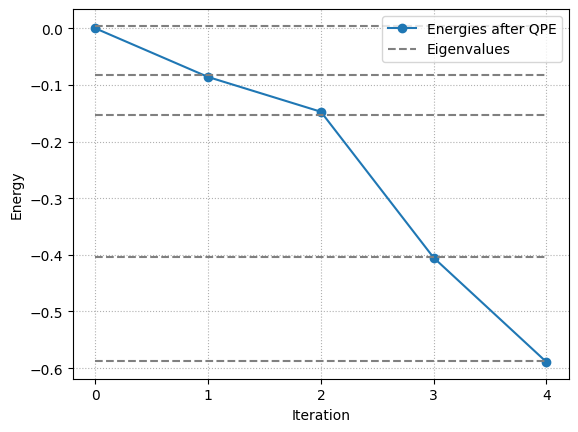

In [43]:
import matplotlib.pyplot as plt

# Classically computed eigenvalues
eigvals_cl = np.linalg.eigvalsh(H.to_array())

# Plot comparison
fig, ax = plt.subplots()
ax.plot(range(N_cycles+1), energy_steps, marker='o', label='Energies after QPE')
ax.hlines(y=eigvals_cl[:init_index+1], xmin=0, xmax=N_cycles, 
          color='gray', linestyle='--', label='Eigenvalues')
ax.set_ylabel('Energy')
ax.set_xlabel('Iteration')
ax.set_xticks(range(N_cycles+1))
ax.legend(loc='upper right')
ax.grid(ls=':')
plt.show()

Let us look at the results: The plot shows the iterations on the x-axis and the energy on the y-axis. We start from $E_4 \approx 0.05$ at iteration 0. At each step we see an energy reduction that coincides with the grey lines. These represent the eigenvalues we calculated clasically beforehand. So, after each iteration we land in an eigenstate with the next lower energy. Thus, after the last cycle, the system is in the ground state!

## Conclusion

In this tutorial we uses a quantum algorithm based on block encodings to move a system from an exited state without any overlap with the ground state into the lowest energy state. Here are some things we learned along the way:

* We understood the algorithm theoretically and applied it to the XY Model. 
* We used the Jasp pipeline to combine mid-circuit measurements with calculations that depend on the measurement results. 
* While the perturbation operator can in theory induce transitions to lower energy states, this might result in long evolution times that are difficult to simulate. 

We find that this is an exiting application of block encodings for ground state preparation!